### Task 5: Pre-trained Language Models (25%)
In this task, you will fine-tune one or two pre-trained transformer-based language models on
the provided dataset and evaluate their performance in both the binary and multiclass
sentiment classification settings. You may choose from a range of widely used pre-trained
models, such as BERT or RoBERTa.

When fine-tuning the models, carefully consider important training parameters such as
learning rate, batch size, number of epochs, and regularization strategies. The goal is to adapt
the model to the dataset while preserving useful knowledge from pre-training and avoiding
overfitting.

In your report, clearly describe the selected models, the training setup, and the experimental
procedure. In addition, compare the results of the fine-tuned transformer models with the
classical machine learning approaches from the previous tasks. Discuss differences in
performance, typical error cases, and the computational cost of training and inference, with
particular emphasis on model behavior rather than only final performance scores.

In [69]:
# !pip install torch transformers datasets accelerate scikit-learn

In [ ]:
import pandas as pd

# load the original tweet sentiment dataset using Latin-1 encoding
df_original = pd.read_csv("../data/TweetSentiment.csv", encoding="latin-1")
df = df_original
df = df.dropna(subset=['text'])

# define mappings between sentiment labels and numerical IDs
label2id = {'negative': 0, 'neutral': 1, 'positive': 2}
id2label = {0: 'negative', 1: 'neutral', 2: 'positive'}

# transform sentiment string to id
df['labels'] = df['sentiment'].map(label2id)

print(df['labels'].isna().sum())

0


In [71]:
# train / test split
from sklearn.model_selection import train_test_split
df = df[['text', 'labels']]

test_size = 0.2
random_state=42
train_df, test_df = train_test_split(df, test_size=test_size, stratify=df['labels'], random_state=random_state)

print(train_df['labels'].value_counts(normalize=True))
print(test_df['labels'].value_counts(normalize=True))

labels
1    0.404567
2    0.312273
0    0.283160
Name: proportion, dtype: float64
labels
1    0.404476
2    0.312409
0    0.283115
Name: proportion, dtype: float64


In [72]:
# tokenization

from transformers import DistilBertTokenizer, DistilBertForSequenceClassification, DataCollatorWithPadding
from datasets import Dataset

# load the tokenizer associated with the pretrained DistilBERT model
tokenizer = DistilBertTokenizer.from_pretrained('distilbert-base-uncased')

# convert into Dataset objects
train_dataset = Dataset.from_pandas(train_df, preserve_index=False)
test_dataset = Dataset.from_pandas(test_df, preserve_index=False)

max_length = 64

def tokenize(batch):
    return tokenizer(batch["text"], truncation=True, max_length=max_length)

train_dataset = train_dataset.map(tokenize, batched=True)
test_dataset = test_dataset.map(tokenize, batched=True)

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

Map: 100%|██████████| 5496/5496 [00:00<00:00, 68194.62 examples/s]


In [73]:
from transformers import set_seed

set_seed(42)
model = DistilBertForSequenceClassification.from_pretrained("distilbert-base-uncased", num_labels=3, id2label=id2label, label2id=label2id)

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 1213.86it/s]
[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [74]:
# compute metrics

import numpy as np
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

def compute_metrics(eval_pred):
    logits, true_labels = eval_pred
    preds = np.argmax(logits, axis=1)
    acc_score = accuracy_score(true_labels, preds)
    precision, recall, f1, _ = precision_recall_fscore_support(true_labels, preds, average='macro')

    return {'accuracy': acc_score, 'precision': precision, 'recall': recall, 'f1': f1}

In [75]:
# training arguments

from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir='./distilbert-3class', 
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=3,
    weight_decay=0.01,
    warmup_ratio=0.1,
    eval_strategy='epoch',
    logging_strategy='epoch',
    report_to='none',
    load_best_model_at_end=True,
    metric_for_best_model='f1',
    save_strategy='epoch')

[transformers] warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


In [76]:
# trainer

from transformers import Trainer

trainer = Trainer(
    model=model, 
    args=training_args, 
    train_dataset=train_dataset, 
    eval_dataset=test_dataset, 
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    processing_class=tokenizer)

In [77]:
result = trainer.train()

print(result.metrics)

/Users/bensc/Documents/MI-Master/FS_1/NLP/Projects/project_1/.venv/lib/python3.11/site-packages/torch/utils/data/dataloader.py:752: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.651406,0.546892,0.775291,0.791931,0.769805,0.776720
2,0.438621,0.549565,0.793304,0.795231,0.799164,0.796810
3,0.327481,0.581245,0.793486,0.796034,0.797390,0.796656


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.38it/s]
/Users/bensc/Documents/MI-Master/FS_1/NLP/Projects/project_1/.venv/lib/python3.11/site-packages/torch/utils/data/dataloader.py:752: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)
Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.13it/s]
/Users/bensc/Documents/MI-Master/FS_1/NLP/Projects/project_1/.venv/lib/python3.11/site-packages/torch/utils/data/dataloader.py:752: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)
Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.04it/s]


{'train_runtime': 1400.1698, 'train_samples_per_second': 47.103, 'train_steps_per_second': 2.944, 'total_flos': 672491021198400.0, 'train_loss': 0.4725026996433012, 'epoch': 3.0}


In [78]:
trainer.evaluate()

/Users/bensc/Documents/MI-Master/FS_1/NLP/Projects/project_1/.venv/lib/python3.11/site-packages/torch/utils/data/dataloader.py:752: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.327481,0.549565,3,0.793304,0.795231,0.799164,0.796810


{'eval_loss': 0.549565315246582,
 'eval_accuracy': 0.7933042212518195,
 'eval_precision': 0.7952310967597821,
 'eval_recall': 0.799164465237367,
 'eval_f1': 0.7968097590089108}

/Users/bensc/Documents/MI-Master/FS_1/NLP/Projects/project_1/.venv/lib/python3.11/site-packages/torch/utils/data/dataloader.py:752: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


              precision    recall  f1-score   support

    negative       0.77      0.82      0.80      1556
     neutral       0.77      0.74      0.76      2223
    positive       0.84      0.83      0.84      1717

    accuracy                           0.79      5496
   macro avg       0.80      0.80      0.80      5496
weighted avg       0.79      0.79      0.79      5496

Time: 8.464368104934692


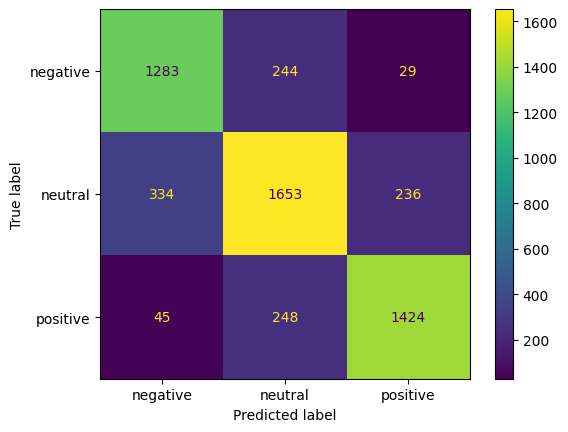

In [79]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, confusion_matrix
import time

start = time.time()
pred_output = trainer.predict(test_dataset)
end = time.time()

classes = np.argmax(pred_output.predictions, axis=-1)

y_true = pred_output.label_ids

report = classification_report(y_true, classes, target_names=['negative','neutral','positive'])

print(report)

# display total time
print(f"Time: {end-start}")

# compute and visualize the confusion matrix
conf_matrix = confusion_matrix(y_true, classes)
conf_matrix_display = ConfusionMatrixDisplay(confusion_matrix = conf_matrix, display_labels = ['negative', 'neutral', 'positive'])
conf_matrix_display.plot()

In [80]:
df_mismatch = pd.DataFrame({'text': test_df['text'].values, 'true': y_true, 'predicted': classes})

df_mismatch = df_mismatch[df_mismatch['true'] != df_mismatch['predicted']]

print(df_mismatch.sample(10))

print('\n')
print(len(df_mismatch))

                                                   text  true  predicted
3653   Haha! Night man, and no, but Im sure I`ll mee...     1          2
4313   I assume you mean 2nd item with 3 nested line...     0          1
1342   no juice here, I didntb even let him use my c...     1          0
3892  _ haha tell me about. I`ve had this feeling ev...     1          2
1600  traveling alone makes i meet new people,new ci...     2          1
509   I miss my dog  r.i.p.Batman... Yeah, Batman (I...     0          1
2753  Just got home from morongo.. Havin a corona  W...     1          2
248   i want to go out tonight, but i ain`t go no mo...     0          1
3514   haha yeah this is improving my nite big time!...     2          1
1123            haha I fail  just remember sohcahtoa xD     1          0


1136


In [81]:
# binary
df_binary = df_original[df_original['sentiment'] != 'neutral']
df_binary = df_binary[['text', 'sentiment']]

label2id_binary = {'negative': 0, 'positive': 1}
id2label_binary = {0: 'negative', 1: 'positive'}

# transform sentiment string to id
df_binary['labels'] = df_binary['sentiment'].map(label2id_binary)

df_binary.sample(15)

,text,sentiment,labels
6247,I saw your tweet a couple of weeks ago that h...,positive,1
4194,Good Luck!!! keep rockin!,positive,1
11666,"Let us know what happens, poor little guy.",negative,0
9073,is sad his new SB6 CD`s got nicked,negative,0
22929,"Awww, thanks Jon! I appreciate that",positive,1
4134,britain is ****,negative,0
16730,Everyone we have another hater,negative,0
21602,Watching French Open tennis - sad to see Venus...,negative,0
5789,just woke up and feeling real good cause of kr...,positive,1
5161,oh yeah...haven`t seem that in ages!! got to ...,positive,1


In [82]:
train_df_binary, test_df_binary = train_test_split(df_binary, test_size=0.2, random_state=42, stratify=df_binary['labels'])

print(train_df_binary['labels'].value_counts(normalize=True))
print(test_df_binary['labels'].value_counts(normalize=True))

print(f"\nDF binary size: {len(df_binary)}")
print(f"Test DF binary size: {len(test_df_binary)}")

labels
1    0.524446
0    0.475554
Name: proportion, dtype: float64
labels
1    0.524595
0    0.475405
Name: proportion, dtype: float64

DF binary size: 16363
Test DF binary size: 3273


In [83]:
set_seed(42)
model_binary = DistilBertForSequenceClassification.from_pretrained("distilbert-base-uncased", num_labels=2, id2label=id2label_binary, label2id=label2id_binary)

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 5088.82it/s]
[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [84]:
training_args_binary = TrainingArguments(
    output_dir='./distilbert-2class', 
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=3,
    weight_decay=0.01,
    warmup_ratio=0.1,
    eval_strategy='epoch',
    logging_strategy='epoch',
    report_to='none',
    load_best_model_at_end=True,
    metric_for_best_model='f1',
    save_strategy='epoch')

[transformers] warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


In [85]:
train_dataset_binary = Dataset.from_pandas(train_df_binary, preserve_index=False)
test_dataset_binary = Dataset.from_pandas(test_df_binary, preserve_index=False)

train_dataset_binary = train_dataset_binary.map(tokenize, batched=True)
test_dataset_binary = test_dataset_binary.map(tokenize, batched=True)

Map: 100%|██████████| 3273/3273 [00:00<00:00, 60974.93 examples/s]


In [86]:
trainer_binary = Trainer(
    model=model_binary,
    args=training_args_binary,
    train_dataset=train_dataset_binary,
    eval_dataset=test_dataset_binary,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    processing_class=tokenizer)

In [87]:
result_binary = trainer_binary.train()

print(result_binary .metrics)

/Users/bensc/Documents/MI-Master/FS_1/NLP/Projects/project_1/.venv/lib/python3.11/site-packages/torch/utils/data/dataloader.py:752: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.300764,0.212530,0.927284,0.927555,0.928554,0.927255
2,0.142744,0.227890,0.935839,0.935558,0.935894,0.935709
3,0.088233,0.252439,0.936450,0.936147,0.936567,0.936328


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.90it/s]
/Users/bensc/Documents/MI-Master/FS_1/NLP/Projects/project_1/.venv/lib/python3.11/site-packages/torch/utils/data/dataloader.py:752: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)
Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.87it/s]
/Users/bensc/Documents/MI-Master/FS_1/NLP/Projects/project_1/.venv/lib/python3.11/site-packages/torch/utils/data/dataloader.py:752: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)
Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.47it/s]


{'train_runtime': 821.5482, 'train_samples_per_second': 47.8, 'train_steps_per_second': 2.991, 'total_flos': 398985077891784.0, 'train_loss': 0.17724723024100467, 'epoch': 3.0}


In [88]:
trainer_binary.evaluate()

/Users/bensc/Documents/MI-Master/FS_1/NLP/Projects/project_1/.venv/lib/python3.11/site-packages/torch/utils/data/dataloader.py:752: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.088233,0.252439,3,0.936450,0.936147,0.936567,0.936328


{'eval_loss': 0.252439022064209,
 'eval_accuracy': 0.9364497402994195,
 'eval_precision': 0.9361465710078356,
 'eval_recall': 0.9365667759124316,
 'eval_f1': 0.9363281980681027}

/Users/bensc/Documents/MI-Master/FS_1/NLP/Projects/project_1/.venv/lib/python3.11/site-packages/torch/utils/data/dataloader.py:752: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


              precision    recall  f1-score   support

    negative       0.93      0.94      0.93      1556
    positive       0.94      0.93      0.94      1717

    accuracy                           0.94      3273
   macro avg       0.94      0.94      0.94      3273
weighted avg       0.94      0.94      0.94      3273

Time: 5.080458879470825


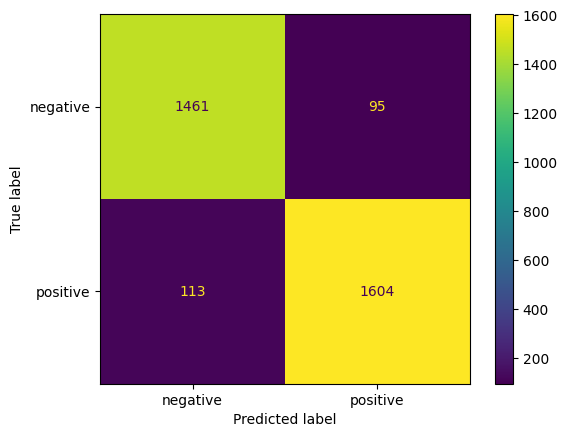

In [89]:
start = time.time()
pred_output_binary = trainer_binary.predict(test_dataset_binary)
end = time.time()

classes_binary = np.argmax(pred_output_binary.predictions, axis=-1)

y_true_binary = pred_output_binary.label_ids

report_binary = classification_report(y_true_binary, classes_binary, target_names=['negative', 'positive'])

print(report_binary)

print(f"Time: {end-start}")


conf_matrix = confusion_matrix(y_true_binary, classes_binary)
conf_matrix_display = ConfusionMatrixDisplay(confusion_matrix = conf_matrix, display_labels = ['negative', 'positive'])
conf_matrix_display.plot()